**ASSIGNMENT - 3**

# Implement an LSTM-based sentiment Analysis system with an Attention layer for US Airline Tweets Dataset

In [1]:
%pip install -q tensorflow numpy pandas matplotlib scikit-learn kagglehub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, SpatialDropout1D, Bidirectional, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)

I0000 00:00:1791729317.710959  186788 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791729317.760051  186788 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791729319.598100  186788 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter
file_path = "Tweets.csv"
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "crowdflower/twitter-airline-sentiment",
  file_path,
)
df = df[['text', 'airline_sentiment']].dropna()
df = df.drop_duplicates(subset='text')   # duplicate tweets could leak between train and test
print(df.head(5))
print(df.columns)
print(df.shape)

/home/rito/ju_lab/ks_lab/exp3/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


                                                text airline_sentiment
0                @VirginAmerica What @dhepburn said.           neutral
1  @VirginAmerica plus you've added commercials t...          positive
2  @VirginAmerica I didn't today... Must mean I n...           neutral
3  @VirginAmerica it's really aggressive to blast...          negative
4  @VirginAmerica and it's a really big bad thing...          negative
Index(['text', 'airline_sentiment'], dtype='str')
(14427, 2)


In [4]:
def clean_text(t):
    t = t.lower()
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"http\S+|www\S+", " ", t)
    t = re.sub(r"n't", " not", t)                  # keep negation: didn't -> did not
    t = re.sub(r"'(s|re|ve|ll|d|m)\b", " ", t)
    t = re.sub(r"([!?])", r" \1 ", t)              # keep ! and ? as separate tokens
    t = re.sub(r"[^a-z!?\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

df['clean_text'] = df['text'].apply(clean_text)
print(df[['text', 'clean_text']].head())

                                                text  \
0                @VirginAmerica What @dhepburn said.   
1  @VirginAmerica plus you've added commercials t...   
2  @VirginAmerica I didn't today... Must mean I n...   
3  @VirginAmerica it's really aggressive to blast...   
4  @VirginAmerica and it's a really big bad thing...   

                                          clean_text  
0                                          what said  
1  plus you added commercials to the experience t...  
2  i did not today must mean i need to take anoth...  
3  it really aggressive to blast obnoxious entert...  
4             and it a really big bad thing about it  


In [5]:
labels = pd.get_dummies(df['airline_sentiment']).astype(int)
class_names = list(labels.columns)
y = labels.values
X_text = df['clean_text'].values

X_temp, X_test_text, y_temp, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y.argmax(axis=1)
)
X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp.argmax(axis=1)
)

print("Train:", len(X_train_text), "Val:", len(X_val_text), "Test:", len(X_test_text))

Train: 8655 Val: 2886 Test: 2886


In [6]:
vocab_size = 10000
max_length = 40

# filters='' so the ! and ? tokens kept by clean_text are not stripped again
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>", filters='')
tokenizer.fit_on_texts(X_train_text)

def encode(texts):
    seq = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=max_length, padding='post', truncating='post')

X_train = encode(X_train_text)
X_val = encode(X_val_text)
X_test = encode(X_test_text)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)

X_train: (8655, 40) X_val: (2886, 40) X_test: (2886, 40)


## Model with Attention layer

In [7]:
class AttentionPooling(layers.Layer):
    """Additive (Bahdanau-style) attention that collapses the time axis and respects the padding mask."""
    def __init__(self, units=64, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True
        self.score_dense = Dense(units, activation='tanh')
        self.score_out = Dense(1, use_bias=False)

    def attention_weights(self, inputs, mask=None):
        scores = self.score_out(self.score_dense(inputs))           # (batch, time, 1)
        if mask is not None:
            mask = tf.cast(mask, scores.dtype)[..., tf.newaxis]
            scores += (1.0 - mask) * -1e9                            # padding tokens get ~0 weight
        return tf.nn.softmax(scores, axis=1)                         # weights over time sum to 1

    def call(self, inputs, mask=None):
        weights = self.attention_weights(inputs, mask)
        return tf.reduce_sum(weights * inputs, axis=1)               # (batch, features)

    def compute_mask(self, inputs, mask=None):
        return None  # time axis is gone, so no mask downstream

    def get_config(self):
        return {**super().get_config(), "units": self.units}

In [8]:
embedding_dim = 128

inputs = Input(shape=(max_length,))
x = Embedding(input_dim=vocab_size, output_dim=embedding_dim, mask_zero=True)(inputs)  # mask the padding zeros
x = SpatialDropout1D(0.3)(x)
x = Bidirectional(LSTM(64, return_sequences=True), name='bilstm')(x)  # keep every timestep for attention
x = AttentionPooling(64, name='attention')(x)
x = Dropout(0.5)(x)
outputs = Dense(3, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

E0000 00:00:1791729322.652518  186788 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 40)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 40, 128)   │  1,280,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout1d   │ (None, 40, 128)   │          0 │ embedding[0][0]   │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 40)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm              │ (None, 40, 128)   │     98,816 │ spatial_dropout1… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 128)       │      8,320 │ bilstm[0][0],     │
│ (AttentionPooling)  │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ attention[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3)         │        387 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,387,523 (5.29 MB)

 Trainable params: 1,387,523 (5.29 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# EarlyStopping restores the weights from the epoch with the lowest val_loss,
# so the evaluated model is the best one, not the last (most overfitted) one.
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=10,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 34s 36ms/step - accuracy: 0.7566 - loss: 0.6144 - val_accuracy: 0.7911 - val_loss: 0.5210 - learning_rate: 0.0010
Epoch 2/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 35s 40ms/step - accuracy: 0.8583 - loss: 0.3845 - val_accuracy: 0.7848 - val_loss: 0.5294 - learning_rate: 0.0010
Epoch 3/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 33s 39ms/step - accuracy: 0.9040 - loss: 0.2672 - val_accuracy: 0.7827 - val_loss: 0.5840 - learning_rate: 0.0010
Epoch 4/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step - accuracy: 0.9430 - loss: 0.1711 - val_accuracy: 0.7744 - val_loss: 0.6904 - learning_rate: 5.0000e-04
Epoch 5/50
866/866 ━━━━━━━━━━━━━━━━━━━━ 32s 37ms/step - accuracy: 0.9562 - loss: 0.1293 - val_accuracy: 0.7696 - val_loss: 0.8030 - learning_rate: 5.0000e-04


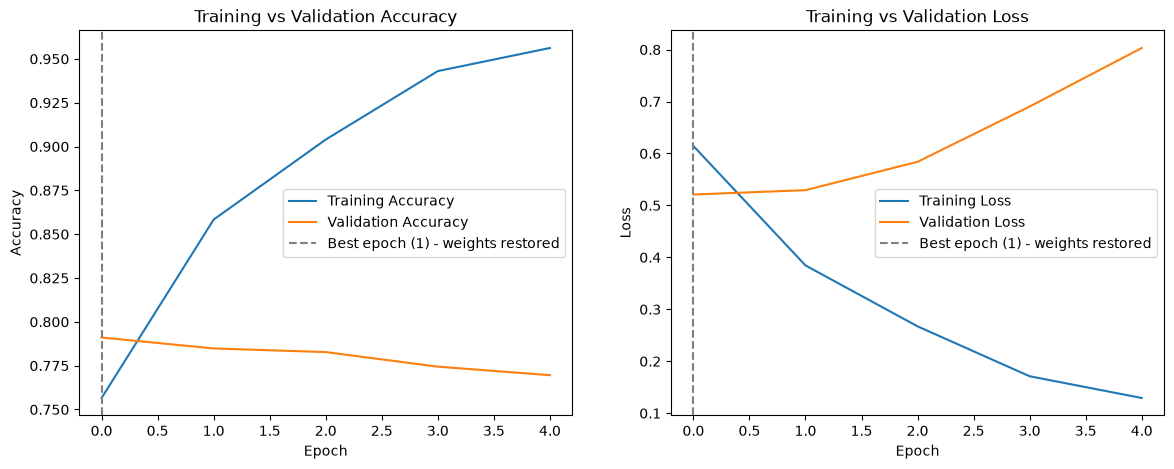

In [10]:
best_epoch = int(np.argmin(history.history['val_loss']))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history.history['accuracy'], label='Training Accuracy')
ax[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].set_title('Training vs Validation Accuracy'); ax[0].legend()

ax[1].plot(history.history['loss'], label='Training Loss')
ax[1].plot(history.history['val_loss'], label='Validation Loss')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
ax[1].set_title('Training vs Validation Loss'); ax[1].legend()

for a in ax:
    a.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch + 1}) - weights restored')
    a.legend()

plt.show()

In [11]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("Test Loss     :", loss)
print("Test Accuracy :", accuracy)

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

Test Loss     : 0.5126873850822449
Test Accuracy : 0.7969508171081543
91/91 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

    negative       0.83      0.93      0.88      1816
     neutral       0.73      0.46      0.57       612
    positive       0.71      0.71      0.71       458

    accuracy                           0.80      2886
   macro avg       0.76      0.70      0.72      2886
weighted avg       0.79      0.80      0.78      2886



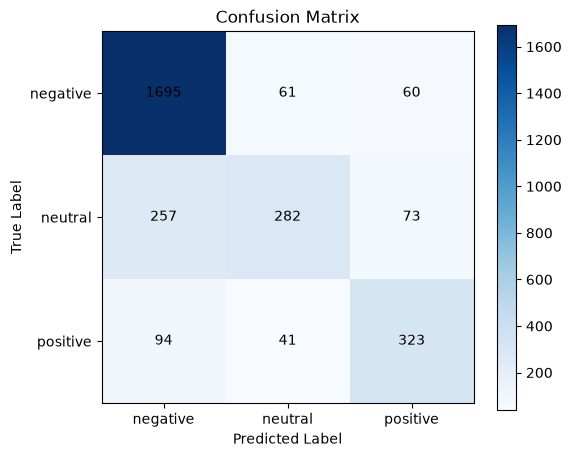

In [12]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(range(3), class_names)
plt.yticks(range(3), class_names)
plt.colorbar()

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='black')

plt.show()

In [13]:
def predict_sentiment(text):
    padded = encode([clean_text(text)])
    probs = model.predict(padded, verbose=0)[0]
    return class_names[int(np.argmax(probs))], probs

samples = [
    "The flight was amazing and the staff were very helpful",
    "Worst airline ever, my luggage was lost and nobody helped",
    "What time does the flight to Denver depart?"
]

for s in samples:
    label, probs = predict_sentiment(s)
    print(f"{s}\n  -> {label}  {dict(zip(class_names, probs.round(3)))}\n")

The flight was amazing and the staff were very helpful
  -> positive  {'negative': np.float32(0.058), 'neutral': np.float32(0.021), 'positive': np.float32(0.921)}

Worst airline ever, my luggage was lost and nobody helped
  -> negative  {'negative': np.float32(0.987), 'neutral': np.float32(0.004), 'positive': np.float32(0.009)}

What time does the flight to Denver depart?
  -> neutral  {'negative': np.float32(0.465), 'neutral': np.float32(0.491), 'positive': np.float32(0.044)}



## Attention weights visualization

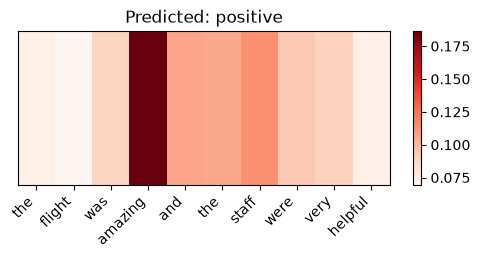

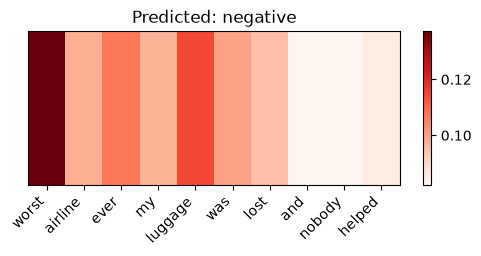

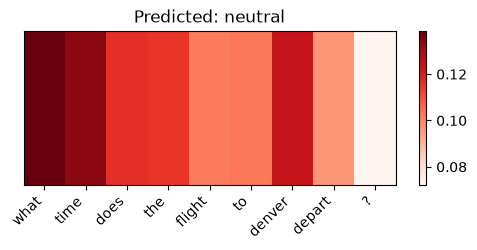

In [14]:
# Which words did the model attend to?
bilstm_model = Model(model.input, model.get_layer('bilstm').output)
attention = model.get_layer('attention')

def show_attention(text):
    cleaned = clean_text(text)
    padded = encode([cleaned])
    seq_out = bilstm_model.predict(padded, verbose=0)
    mask = padded != 0
    weights = attention.attention_weights(seq_out, mask).numpy()[0, :, 0]

    n = int(mask.sum())
    words = [tokenizer.index_word.get(i, '<OOV>') for i in padded[0][:n]]
    label, probs = predict_sentiment(text)

    plt.figure(figsize=(max(6, n * 0.6), 2))
    plt.imshow(weights[:n][np.newaxis, :], cmap='Reds', aspect='auto')
    plt.xticks(range(n), words, rotation=45, ha='right')
    plt.yticks([])
    plt.title(f"Predicted: {label}")
    plt.colorbar()
    plt.show()

for s in samples:
    show_attention(s)